# Number theory 2: Prime factoring

*Learning path: number theory, part 2 of 7.* [Index](README.md) · Previous: [Divisibility and primes](01-divisibility-and-primes.ipynb) · Next: [Algebraic factoring](03-algebraic-factoring.ipynb)

Multiplying two primes takes a second, even by hand: $1009 \cdot 9973 = 10\,062\,757$. Going back, from
$10\,062\,757$ to its two primes, is much harder, and for numbers with a few hundred digits nobody knows how to do it
at all. That one-way street is what protects most of the internet (lesson 5). In this lesson you build the classic
factoring methods yourself, see why each one works, and measure how fast it is:

* **trial division**, and why you can stop at $\sqrt n$,
* **Fermat's method**, which is fast when the two factors are close,
* **Pollard's rho method**, which uses the birthday paradox to find a factor $p$ in about $\sqrt p$ steps,
* **primality tests**: how to know a number is prime without factoring it (Fermat and Miller–Rabin),
* how Galileo's `factor` combines these, and where the record attempts stand.

Every method is written as a short Galileo function, so you can change it and watch what happens.

## 1. Trial division

The obvious method: try dividing $n$ by $2, 3, 4, 5, \ldots$ until one divides. You can stop at $\sqrt n$: if
$n = a\cdot b$ with both $a$ and $b$ larger than $\sqrt n$, then $ab > n$. So if no number up to $\sqrt n$ divides
$n$, then $n$ is prime.

Written as a function, `smallest(n, d)` looks for the smallest divisor of $n$, starting the search at $d$:

* if $d\cdot d > n$, we have passed $\sqrt n$ without finding a divisor, so $n$ itself is prime: the answer is $n$;
* otherwise, if $d$ divides $n$ (remainder `mod(n, d)` is 0), the answer is $d$;
* otherwise, try the next candidate: `smallest(n, d + 1)`.

`if(condition, a, b)` gives $a$ when the condition is true and $b$ otherwise; the two `if`s are nested to make three
cases. We start the search at $d = 2$:

In [1]:
smallest(n, d) := if(d*d > n, n, if(mod(n, d) == 0, d, smallest(n, d + 1)));
smallest(91, 2)
smallest(97, 2)
smallest(10062757, 2)

7
97
1009

$91 = 7 \cdot 13$ looks prime but isn't; 97 is prime; and $10\,062\,757$ has smallest factor 1009, as it should.

To factor completely, divide by the smallest factor and repeat. `tf(n)` ("trial factor") returns the list of prime
factors: for $n = 1$ the empty list `[]`, otherwise the smallest factor $p$ followed by the factors of $n/p$. Writing
`[a, list]` puts $a$ in front of a list:

In [2]:
tf(n) := if(n == 1, [], [smallest(n, 2), tf(n/smallest(n, 2))]);
tf(5040)
tf(10062757)
tf(2^32 + 1)

2	2	2	2	3	3	5	7
1009	9973
641	6700417

Galileo's built-in `factor` agrees and writes the same thing compactly:

In [3]:
factor(5040)

2^4 * 3^2 * 5 * 7

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

### How long does it take?

To find the factor $p$, trial division tries every number from 2 to $p$: about $p$ steps. The worst case is a product
of two primes of the same size, $n = p\cdot q$ with $p \approx q \approx \sqrt n$. So a number with 20 digits needs about
$10^{10}$ trial divisions and one with 600 digits (a real cryptographic key) about $10^{300}$, more than the number of
atoms in the universe ($10^{80}$) squared and then some. Here is a product of two 7-digit primes; trial division needs
a million steps, which takes Galileo a few seconds:

In [4]:
smallest(1000003*1000033, 2)

1000003

Small improvements help: only try 2 and the odd numbers (half the work), or only primes. But the number of steps still
grows like $\sqrt n$, and that is hopeless for large $n$. We need ideas.

## 2. Fermat's method: differences of squares

In 1643 Fermat wrote to Mersenne how he factored $n = 2\,027\,651\,281$. His idea: if

$$n = a^2 - b^2 \quad\text{then}\quad n = (a - b)(a + b).$$

So look for an $a$ for which $a^2 - n$ is a perfect square $b^2$. Start with the smallest $a$ with $a^2 > n$, which is
just above $\sqrt n$, and count up. `isqrt(m)` is the whole-number square root ($\sqrt m$ rounded down), so $m$ is a
perfect square exactly when `isqrt(m)^2 == m`. A small example first, $8051$:

In [5]:
isqrt(8051)
90^2 - 8051
isqrt(49)

89

> `pollard`: One factor of n found by Pollard's rho method, and the integer square root (largest k with k^2 <= n).

49
7

> `pollard`: One factor of n found by Pollard's rho method, and the integer square root (largest k with k^2 <= n).

$90^2 - 8051 = 49 = 7^2$, so $8051 = 90^2 - 7^2 = (90 - 7)(90 + 7) = 83 \cdot 97$. On the first try!

For Fermat's number we make a table: the columns are $a$, then $a^2 - n$, then its whole-number square root, then a
check whether $a^2 - n$ is a perfect square. Rows run from $a = 45030$ (just above $\sqrt n \approx 45029.5$) to
$45041$:

In [6]:
n = 2027651281;
isqrt(n)
table([a, a^2 - n, isqrt(a^2 - n), isqrt(a^2 - n)^2 == a^2 - n], a, 45030, 45041)

45029

> `pollard`: One factor of n found by Pollard's rho method, and the integer square root (largest k with k^2 <= n).

45030	49619	222	false
45031	139680	373	false
45032	229743	479	false
45033	319808	565	false
45034	409875	640	false
45035	499944	707	false
45036	590015	768	false
45037	680088	824	false
45038	770163	877	false
45039	860240	927	false
45040	950319	974	false
45041	1040400	1020	true

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

In the twelfth row, $a = 45041$: $a^2 - n = 1\,040\,400 = 1020^2$. So

$$2\,027\,651\,281 = (45041 - 1020)(45041 + 1020) = 44021 \cdot 46061.$$

As a function, `fermat(n, a)` returns the two factors, or tries the next $a$:

In [7]:
fermat(n, a) := if(isqrt(a^2 - n)^2 == a^2 - n, [a - isqrt(a^2 - n), a + isqrt(a^2 - n)], fermat(n, a + 1));
fermat(2027651281, isqrt(2027651281) + 1)
fermat(1000003*1000033, isqrt(1000003*1000033) + 1)
clear

44021	46061
1000003	1000033

The second example, which cost trial division a million steps, is found instantly: the factors $1000003$ and
$1000033$ are close together, so $a = (p + q)/2$ is close to $\sqrt n$. The catch: when the factors are far apart,
Fermat's method is even slower than trial division. Cryptographers avoid it simply by choosing primes that are not too
close. Fermat's idea lives on in the fastest modern methods (the quadratic and number field sieves), which build a
difference of squares $a^2 \equiv b^2$ (mod $n$) from many small pieces.

## 3. Pollard's rho method

### The birthday paradox

In a room of 23 people, the chance that two share a birthday is more than one half, although there are 365 possible
birthdays. The reason: 23 people form $23\cdot 22/2 = 253$ pairs, and each pair has a 1 in 365 chance. In general,
picking random numbers below $p$, the first repeat comes after about $\sqrt{p}$ picks, not $p$. The table shows the
chance of no shared birthday among $k$ people, $\frac{365}{365}\cdot\frac{364}{365}\cdots\frac{365-k+1}{365}$, for
$k = 10, 15, \ldots, 40$ people (`prod(expr, j, a, b)` multiplies like `sum` adds; the table runs over $m$ with
$k = 5m$):

In [8]:
table([5*m, eval(prod((365 - j)/365, j, 0, 5*m - 1))], m, 2, 8)

10	0.8830518222889223
15	0.7470986802363135
20	0.5885616164194201
25	0.4313002960305361
30	0.2936837572807313
35	0.18561676112528477
40	0.10876819018205101

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

### A walk that hides the factor

John Pollard's idea (1975): walk through the numbers mod $n$ with the rule

$$x_0 = 2, \qquad x_{k+1} = \operatorname{mod}(x_k^2 + 1,\ n).$$

The steps look random. `iterate(rule, x, start, k)` lists $x_0, x_1, \ldots, x_k$; here for $n = 8051 = 83\cdot97$:

In [9]:
iterate(mod(x^2 + 1, 8051), x, 2, 12)

2	5	26	677	7474	2839	871	1848	1481	3490	6989	705	5915

> `iterate`: x0, f(x0), f(f(x0)), ...

Now look at the same walk modulo the factors $83$ and $97$ (which, in a real problem, we don't know yet). Taking
remainders mod 97 commutes with squaring and adding, so these are the remainders of the numbers above:

In [10]:
iterate(mod(x^2 + 1, 97), x, 2, 12)
iterate(mod(x^2 + 1, 83), x, 2, 12)

2	5	26	95	5	26	95	5	26	95	5	26	95

> `iterate`: x0, f(x0), f(f(x0)), ...

2	5	26	13	4	17	41	22	70	4	17	41	22

> `iterate`: x0, f(x0), f(f(x0)), ...

Mod 97 there are only 97 possible values, so the walk must repeat, and by the birthday paradox it repeats after about
$\sqrt{97} \approx 10$ steps. Here it already cycles $5, 26, 95, 5, 26, 95, \ldots$ after one step. Mod 83 it runs
$2, 5, 26, 13$ and then cycles $4, 17, 41, 22, 70$. Drawn as a path, a short tail running into a loop looks like the
Greek letter $\rho$, which gave the method its name.

The plot shows the walk mod 83: across is the step number $k$, up is $x_k$ mod 83. After the four tail steps the same
five values repeat forever. To compute the points, `w(k, p)` is $x_k$ mod $p$, defined recursively: 2 for $k = 0$,
otherwise the rule applied to $x_{k-1}$. The table has one row $[k, x_k \bmod 83]$ per step:

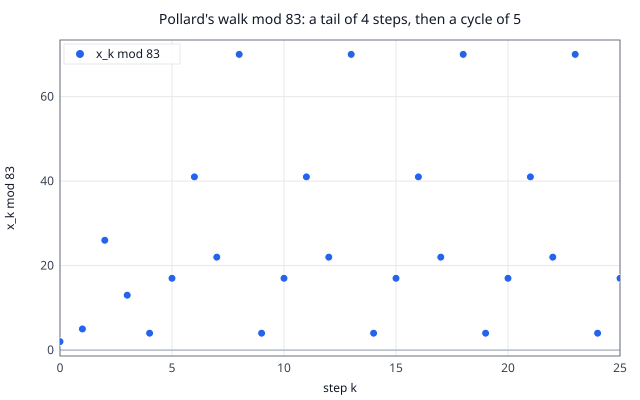

> `title`: A copy of plot p with a title or axis labels.

In [11]:
w(k, p) := if(k == 0, 2, mod(w(k - 1, p)^2 + 1, p));
W = table([k, w(k, 83)], k, 0, 25);
labels(title(legend(scatter(W, [k xk]), "x_k mod 83"), "Pollard's walk mod 83: a tail of 4 steps, then a cycle of 5"), "step k", "x_k mod 83")

### Catching the repeat with a gcd

When $x_i \equiv x_j$ (mod $p$), then $p$ divides $x_i - x_j$, and also divides $n$. So
$\gcd(x_i - x_j, n)$ is a multiple of $p$, usually $p$ itself, and the gcd is cheap to compute with Euclid's algorithm
even though we never knew $p$.

Which pairs $i, j$ should we compare? Checking all pairs is too much work. Floyd's trick, the **tortoise and the
hare**: compare $x_k$ with $x_{2k}$. The hare runs twice as fast, and once both are in the cycle the hare catches up
with the tortoise. The table has the columns $k$, $x_k$, $x_{2k}$ (all mod $n$, as we would really compute them) and
$\gcd(|x_{2k} - x_k|, n)$:

In [12]:
x(k) := if(k == 0, 2, mod(x(k - 1)^2 + 1, 8051));
table([k, x(k), x(2*k), gcd(abs(x(2*k) - x(k)), 8051)], k, 1, 4)

1	5	26	1
2	26	7474	1
3	677	871	97
4	7474	1481	1

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

At $k = 3$ the gcd is 97: a factor, found without trying any divisions. As a function, `rho(n, x, y, k)` keeps the
tortoise $x$ (one step at a time) and the hare $y$ (two steps at a time) and counts the steps $k$; it returns the
factor and the number of steps it took. Starting values: tortoise $x_0 = 2$, hare $x_1 = 5$ (so the hare is one step
ahead), step count 1:

In [13]:
rho(n, x, y, k) := if(gcd(abs(x - y), n) > 1, [gcd(abs(x - y), n), k], rho(n, mod(x^2 + 1, n), mod(mod(y^2 + 1, n)^2 + 1, n), k + 1));
rho(8051, 2, 5, 1)
rho(10062757, 2, 5, 1)
rho(1000003*1000033, 2, 5, 1)

97	3
1009	49
1000033	478

The product of two 7-digit primes, which took trial division a million steps, falls in 478 steps.

### $\sqrt p$ steps

How many steps does rho need to find a prime factor $p$? The birthday paradox predicts about $\sqrt p$. To test it we
multiply $p$ by a prime ten times larger and count the steps, for 29 primes $p$ from about $10^2$ to $10^9$ (each row:
$p$ and the step count; `steps` is `rho` without the factor):

In [14]:
steps(n, x, y, k) := if(gcd(abs(x - y), n) > 1, k, steps(n, mod(x^2 + 1, n), mod(mod(y^2 + 1, n)^2 + 1, n), k + 1));
P(j) := nextprime(floor(10^(j/4)));
S = table([P(j), steps(P(j)*nextprime(10*P(j)), 2, 5, 1)], j, 8, 36);

The numbers range over seven orders of magnitude, so we plot the logarithms: across $\log p$, up $\log(\text{steps})$.
`scatter(S, [p s], [log(p) log(s)])` names the columns $p$ and $s$ and then plots the two expressions in brackets
instead of the raw columns. If steps $\approx \sqrt p$, then $\log(\text{steps}) \approx \frac12 \log p$: a straight line
with slope one half, drawn in red:

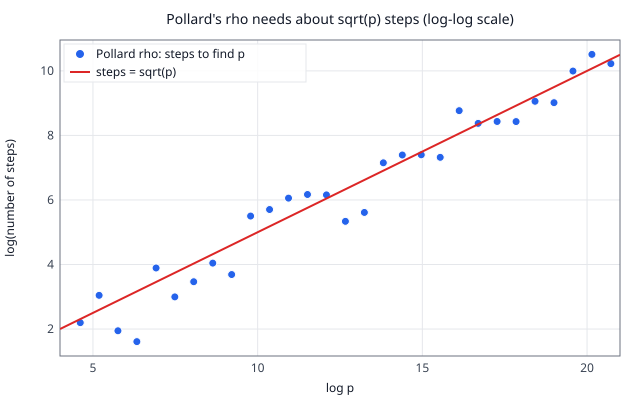

> `title`: A copy of plot p with a title or axis labels.

In [15]:
pl = show(scatter(S, [p s], [log(p) log(s)]), plot(u/2, u, 4, 21));
pl = legend(pl, "Pollard rho: steps to find p", "steps = sqrt(p)");
labels(title(pl, "Pollard's rho needs about sqrt(p) steps (log-log scale)"), "log p", "log(number of steps)")

The points scatter (the walk is random-like, so some primes are lucky), but they follow the line of slope $\frac12$.
Trial division would lie on a line of slope 1, far above: for $p \approx 10^9$ it needs $10^9$ steps, rho about
$3\cdot10^4$.

Galileo's `pollard(n)` runs a faster variant by Richard Brent (1980), which finished the factorization of the eighth
Fermat number $2^{256} + 1$ in 1981:

In [16]:
pollard(1000003*1000033)
pollard(2^64 + 1)

1000033

> `pollard`: One factor of n found by Pollard's rho method, and the integer square root (largest k with k^2 <= n).

274177

> `pollard`: One factor of n found by Pollard's rho method, and the integer square root (largest k with k^2 <= n).

## 4. Is it prime?

Every factoring method needs to know when to stop: when the remaining number is prime. Testing that by trial division
costs $\sqrt n$ steps again. Fermat's little theorem gives a shortcut (lesson 4 explains why it holds): if $p$ is prime,
then

$$a^{p-1} \equiv 1 \pmod p \qquad\text{for every } a \text{ not divisible by } p.$$

`powmod(a, e, n)` computes $a^e$ mod $n$ quickly even for huge $e$ (by repeated squaring; lesson 4). So if
$2^{n-1}$ mod $n$ is not 1, then $n$ is certainly not prime, and we know it without finding a factor:

In [17]:
powmod(2, 97 - 1, 97)
powmod(2, 91 - 1, 91)
powmod(3, 2^67 - 2, 2^67 - 1)

1

> `powmod`: a^b mod n computed by repeated squaring (fast for huge b), and the inverse of a mod n (the x with a*x = 1 mod n).

64

> `powmod`: a^b mod n computed by repeated squaring (fast for huge b), and the inverse of a mod n (the x with a*x = 1 mod n).

95591506202441271281

> `powmod`: a^b mod n computed by repeated squaring (fast for huge b), and the inverse of a mod n (the x with a*x = 1 mod n).

97 passes, 91 fails (so it is composite), and $2^{67} - 1$ fails too (with $a = 3$): it is not prime, although Mersenne
claimed it was in 1644. With $a = 2$ it would have passed, because $2^{67} \equiv 1$ (mod $2^{67} - 1$); numbers of
the form $2^p - 1$ always fool the test with $a = 2$. In 1903 Frank Nelson Cole gave a talk at the American Mathematical Society in which he said nothing at all:
he computed $2^{67} - 1$ on one side of the blackboard, the product $193707721 \cdot 761838257287$ on the other, and the
two agreed. He later said finding the factors took "three years of Sundays".

In [18]:
2^67 - 1
193707721*761838257287
factor(2^67 - 1)

147573952589676412927
147573952589676412927
193707721 * 761838257287

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

### Liars and Carmichael numbers

The test can be fooled: some composite numbers pass it. 561 passes for $a = 2$, although $561 = 3 \cdot 11 \cdot 17$.
Worse, it passes for every $a$ that shares no factor with it; such numbers are **Carmichael numbers**:

In [19]:
powmod(2, 560, 561)
factor(561)
table([a, powmod(a, 560, 561)], a, 2, 7)

1

> `powmod`: a^b mod n computed by repeated squaring (fast for huge b), and the inverse of a mod n (the x with a*x = 1 mod n).

3 * 11 * 17

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

2	1
3	375
4	1
5	1
6	375
7	1

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

(For $a = 3$ and $a = 6$ the answer isn't 1, but only because they share the factor 3 with 561: a test that tries
them has found a factor by luck.)

### The Miller–Rabin test

Gary Miller (1976) and Michael Rabin (1980) found the fix. If $p$ is prime and $x^2 \equiv 1$ (mod $p$), then $p$
divides $(x - 1)(x + 1)$, so $x \equiv \pm 1$: the number 1 has only the two square roots $1$ and $-1$ mod a prime. Write
$n - 1 = 2^s d$ with $d$ odd, and look at the sequence

$$a^d,\ a^{2d},\ a^{4d},\ \ldots,\ a^{2^s d} = a^{n-1} \pmod n,$$

in which each term is the square of the one before. For a prime it ends in 1, and the term before the first 1 must be
$-1$ (or the sequence is 1 from the start). For $n = 561$: $560 = 2^4 \cdot 35$. The table has $k$ and
$2^{35\cdot 2^k}$ mod 561 for $k = 0, \ldots, 4$:

In [20]:
table([k, powmod(2, 35*2^k, 561)], k, 0, 4)

0	263
1	166
2	67
3	1
4	1

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The sequence is $263, 166, 67, 1, 1$: $67^2 \equiv 1$ but $67 \not\equiv \pm 1$ (mod 561), so 561 is not prime. And as a
bonus $\gcd(67 - 1, 561)$ is a factor, because 561 divides $(67 - 1)(67 + 1)$ without dividing either:

In [21]:
gcd(67 - 1, 561)

33

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

For a composite $n$, at least three quarters of all $a$ expose it. Trying 20 values of $a$ leaves a chance below
$4^{-20} \approx 10^{-12}$ of being fooled, and for numbers below $3\cdot10^{24}$ the first twelve primes as $a$ are proven
to be enough; for larger numbers no composite is known that passes all 20 bases. That is what `isprime` does. It
handles 39-digit numbers instantly, where trial division would need $10^{19}$ steps. The first one is $2^{127} - 1$,
which Édouard Lucas proved prime by hand in 1876 with a test of this kind; it stayed the largest known prime for 75
years:

In [22]:
2^127 - 1
isprime(2^127 - 1)
isprime(2^89 - 1)
isprime(10062757)

170141183460469231731687303715884105727
true

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

true

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

false

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

Galileo's whole numbers have no size limit, so the next records are within reach too. In 1952 Raphael Robinson ran a
test of this kind on the SWAC, one of the first computers, and found five new primes in one year: $2^{521} - 1$ (157
digits, found within hours of the program's first run), $2^{607} - 1$, $2^{1279} - 1$, $2^{2203} - 1$ and
$2^{2281} - 1$ (687 digits). $2^{523} - 1$, on the other hand, is not prime:

In [23]:
2^521 - 1
isprime(2^521 - 1)
isprime(2^2281 - 1)
isprime(2^523 - 1)

6864797660130609714981900799081393217269435300143305409394463459185543183397656052122559640661454554977296311391480858037121987999716643812574028291115057151
true

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

true

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

false

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

## 5. Putting it together

Galileo's `factor` (also called `ifactor`) works like this: divide out the small primes by trial division, test the
rest with Miller–Rabin, and split any composite part with Pollard–Brent rho (and Pollard's $p - 1$ method, below),
repeating on each piece. The famous factorizations of the 19th century take a fraction of a second:

In [24]:
factor(2^64 + 1)
factor(10^30 + 1)
factor(1000000000039*10000000000037)

274177 * 67280421310721

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

61 * 101 * 3541 * 9901 * 27961 * 4188901 * 39526741

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

1000000000039 * 10000000000037

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

$2^{64} + 1 = 274177 \cdot 67280421310721$ was found by Fortuné Landry in 1880, at 82, after months of work by hand. The
last one is a product of two 13-digit primes; rho needs about a million steps for it.

### Pollard's $p - 1$ method

By Fermat's little theorem (lesson 4), $a^{p-1} \equiv 1 \pmod p$ for a prime $p$, and so $a^M \equiv 1$ for every
multiple $M$ of $p - 1$. If $p - 1$ has only small prime factors, then $M = $ the product of all small prime powers is
such a multiple, without knowing $p$. Then $p$ divides $a^M - 1$, and $\gcd(a^M - 1, n)$ reveals it (John Pollard,
1974). Here $p$ is a 20-digit prime with a very smooth $p - 1$, hidden in a 50-digit product. Rho would need about
$10^{10}$ steps; $p - 1$ needs a few thousand multiplications:

In [25]:
p = 97767475431570134191;
factor(p - 1)
n = p*nextprime(10^30)
factor(n)

2 * 3^2 * 5 * 7 * 11 * 13 * 17 * 19 * 23 * 29 * 31 * 37 * 41 * 43 * 47 * 53

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

97767475431570134191000000005572746099599497648887
97767475431570134191 * 1000000000000000000000000000057

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

That is why the primes in an RSA key must be chosen so that $p - 1$ has a large prime factor.

### Groups hide the factors

Why does $p - 1$ work at all? The numbers $1, \dots, n - 1$ that share no factor with $n$ form a group under
multiplication mod $n$, written $(\mathbb{Z}/n)^*$. For $n = pq$ the Chinese remainder theorem (lesson 4) says that
working mod $n$ is the same as working mod $p$ and mod $q$ at once:

$$(\mathbb{Z}/n)^* \cong (\mathbb{Z}/p)^* \times (\mathbb{Z}/q)^*,$$

a group of order $p - 1$ times a group of order $q - 1$. The order of an element mod $n$ (the first power that gives 1)
is the lcm of its orders mod $p$ and mod $q$. With $p = 1009$ and $q = 2003$, the order of 3 is 168 mod $p$ and
1001 mod $q$, and mod $n$ it is $\operatorname{lcm}(168, 1001) = 24024$:

In [26]:
p = 1009; q = 2003; n = p*q
multorder(3, p)
multorder(3, q)
multorder(3, n)

2021027
168

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

1001

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

24024

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

A factoring method of this kind looks for an exponent $E$ that kills the group on the $p$ side but not on the $q$
side. Then $3^E \equiv 1 \pmod p$ but not mod $q$, and $\gcd(3^E - 1, n) = p$. Pollard's $p - 1$ takes $E$ = all small
prime powers. `pm1(n, B)` runs it with an explicit bound $B$ and says what happened. For Cole's number $2^{67} - 1$
from section 4, one prime has $p - 1 = 2^3 \cdot 3^3 \cdot 5 \cdot 67 \cdot 2677$, so a bound of 3000 is enough:

In [27]:
pm1(2^67 - 1, 3000)

193707721

> found the factor 193707721: for this prime p, p - 1 has no prime factor above 3000 (p - 1 = 2^3 * 3^3 * 5 * 67 * 2677), so 3^E = 1 mod p for E = lcm(1..3000), and gcd(3^E - 1, n) = p

**Knowing the group order is as hard as factoring.** If you knew the order of $(\mathbb{Z}/n)^*$, which is
$\varphi(n) = (p - 1)(q - 1)$, then $p + q = n - \varphi(n) + 1$, and $p$ and $q$ are the roots of
$x^2 - (p + q)x + n$:

In [28]:
phi = (p - 1)*(q - 1)
s = n - phi + 1
solve(x^2 - s*x + n, x)

2018016
3012
1009	2003

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

So the whole difficulty hides in the group's order. The methods below differ only in which group they use.

**Elliptic curves (Lenstra, 1985).** The weakness of $p - 1$ is that the group mod $p$ is fixed. When $p - 1$ has a
large prime factor, as for $p = 7000000001087$ with $p - 1 = 2 \cdot 3500000000543$, the method is stuck. Lenstra
swapped in the points of an elliptic curve $y^2 = x^3 + ax + b$ mod $p$, which also form a group. By Hasse's theorem,
its order lies between $p + 1 - 2\sqrt p$ and $p + 1 + 2\sqrt p$, and it changes from curve to curve. Each new curve
is a new chance at a group order made of small primes. `ecm(n, curves, B1)` tries random curves with bound B1.
`factor` and `algfactor` also try a few curves after rho, and more when you give `algfactor` a larger effort:

In [29]:
p = 7000000001087;
factor(p - 1)
n = p*nextprime(10^40);
pm1(n)
ecm(n, 100, 2000)

2 * 3500000000543

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

1

> no factor: no prime p of n has p - 1 made only of primes up to 100000 (prime powers up to 100000); try a larger B, or ecm(n), which does not depend on p - 1

7000000001087

> found the factor 7000000001087 on curve 7 of 100: the group of that elliptic curve mod 7000000001087 has an order made of primes up to 2000, plus at most one prime up to 50000

**Class groups of quadratic forms (Gauss, Shanks, Schnorr–Lenstra).** A binary quadratic form
$a x^2 + b x y + c y^2$ has discriminant $D = b^2 - 4ac$. Gauss showed that the forms of one negative discriminant,
counted up to a change of variables, form a finite group, the *class group*. `classgroup(D)` lists one reduced form
for each class, with its order under composition (`composeforms`, `formpow`). The forms of order 2 are called
*ambiguous*. For $D = -4N$, the ambiguous forms other than the identity are exactly the factorizations of $N$. Here
$N = 391$ splits as $17 \cdot 23$ through the form $(17, 0, 23)$, which is $17x^2 + 23y^2$:

In [30]:
classgroup(-4*391)

14

> The class group of discriminant -1564 has **h = 14** classes of primitive forms. Each class has one reduced form $(a, b, c)$, meaning $a x^2 + b x y + c y^2$ with $|b| \le a \le c$.
>
> | form | order | ambiguous |
> |---|---|---|
> | (1, 0, 391) | 1 | yes |
> | (5, -4, 79) | 14 |  |
> | (5, 4, 79) | 14 |  |
> | (7, -2, 56) | 14 |  |
> | (7, 2, 56) | 14 |  |
> | (8, -2, 49) | 7 |  |
> | (8, 2, 49) | 7 |  |
> | (11, -8, 37) | 14 |  |
> | (11, 8, 37) | 14 |  |
> | (13, -10, 32) | 7 |  |
> | (13, 10, 32) | 7 |  |
> | (16, -6, 25) | 7 |  |
> | (16, 6, 25) | 7 |  |
> | (17, 0, 23) | 2 | yes |
>
> 2 ambiguous forms (order 1 or 2). For D = -4N, the ambiguous forms other than the identity are exactly the ways to split N: (17, 0, 23) gives 391 = 17 · 23

To factor $N$, raise a form to a large exponent made of small primes (as in $p - 1$), then square until you reach the
identity. The form one step before it has order 2, so it is ambiguous, and its coefficients reveal a factor
(`classfactor`). This works when the class number has only small prime factors. Shanks' SQUFOF (`squfof`) is a fast
walk through the same forms: it follows the continued fraction of $\sqrt{kN}$ until a square turns up. Both suit
numbers up to about 25 digits:

In [31]:
n = nextprime(10^8)*nextprime(3*10^8);
classfactor(n)
squfof(n)

100000007

> found the factor 100000007: the form (100000007, 0, 300000007) of discriminant -4·1·n has order 2 (it is ambiguous), and ambiguous forms are factorizations

100000007

> found the factor 100000007 after 16258 steps of the continued fraction of sqrt(1·n)

All three groups have about $p$ or $\sqrt N$ elements. A method succeeds when the group's order happens to be made of
small primes, and only ECM lets you keep drawing new groups. The record methods, the quadratic and number field
sieves, work differently: they collect many small factorizations and combine them into Fermat's $a^2 - b^2$.

### The limits

Rho finds a factor $p$ in about $\sqrt p$ steps. A product of two 20-digit primes therefore needs about $10^{10}$
steps. Galileo gives up after about a second of work and says which factors it found and how many digits the unsplit
part has: `factor(nextprime(10^19)*nextprime(10^20))` stops with an error message, although the 40-digit product
itself is computed instantly. Modern methods go much further:

* the **quadratic sieve** (Carl Pomerance, 1981) and the **number field sieve** (1990s) build Fermat's difference of
  squares from many small factorizations; their running time grows more slowly than any power of $n$;
* the elliptic curve method (Hendrik Lenstra, 1985) is rho's successor for finding medium-size factors;
* RSA-250, a 250-digit number, was split in 2020 by the number field sieve after about 2700 core-years of computer
  time. In September 2026, RSA-260 (Eric Lu, Cognition) and then RSA-896, 270 digits (Stephen Weis), were factored
  with GPU versions of the same method. `load(RSA)` loads all the RSA challenge numbers and the known factors;
* a large quantum computer running **Shor's algorithm** (1994) could factor in polynomial time; none big enough
  exists yet.

That gap, multiplying is easy and factoring is hard, is exactly what RSA encryption relies on (lesson 5).

## Summary

* Trial division (`smallest`, `tf`): stop at $\sqrt n$; about $p$ steps to find the factor $p$.
* Fermat: $n = a^2 - b^2 = (a - b)(a + b)$; instant when the factors are close.
* Pollard rho: the walk $x \to x^2 + 1$ repeats mod $p$ after about $\sqrt p$ steps; $\gcd(x_{2k} - x_k, n)$ reveals
  $p$. Built in as `pollard`.
* Primality: Fermat's test `powmod(a, n - 1, n)` can be fooled by Carmichael numbers like 561; Miller–Rabin
  (`isprime`) cannot, in practice.
* Pollard's $p - 1$ finds $p$ quickly when $p - 1$ has only small prime factors (`pm1(n, B)`).
* $(\mathbb{Z}/pq)^* \cong (\mathbb{Z}/p)^* \times (\mathbb{Z}/q)^*$, and knowing a group's order is as hard as
  factoring. ECM (`ecm`) swaps in elliptic curve groups whose order varies; class groups of quadratic forms
  (`classgroup`, `classfactor`, `squfof`) turn elements of order 2 into factors.
* `factor` combines them, on numbers of any size; it gives up when what remains has only large prime factors.

**Try it:** factor $n = 999\,962\,000\,357$ with `fermat` (start at `isqrt(n) + 1`) and with `rho`; which is faster,
and why? Change the walk in `rho` to $x^2 + 2$ or $x^2 - 1$: does it still work? Find the next Carmichael number after
561 by testing `powmod(2, n - 1, n) == 1` and `isprime(n)` in a table. (Hint: it is $1105 = 5\cdot13\cdot17$.)

Next: [Algebraic factoring](03-algebraic-factoring.ipynb): why `factor(10^300 + 1)` finds some factors instantly, and a hunt for identities like Sophie Germain's.

## Sources

1. P. de Fermat, letter to Mersenne (1643), in *Œuvres de Fermat*, Vol. 2, p. 256 (the factorization of 2027651281).
2. J. M. Pollard, "A Monte Carlo method for factorization", *BIT Numerical Mathematics* 15 (1975) 331–334.
3. R. P. Brent and J. M. Pollard, "Factorization of the eighth Fermat number", *Mathematics of Computation* 36 (1981) 627–630.
4. G. L. Miller, "Riemann's hypothesis and tests for primality", *J. Computer and System Sciences* 13 (1976) 300–317; M. O. Rabin, "Probabilistic algorithm for testing primality", *J. Number Theory* 12 (1980) 128–138.
5. F. N. Cole, "On the factoring of large numbers", *Bull. Amer. Math. Soc.* 10 (1903) 134–137.
6. R. Crandall and C. Pomerance, *Prime Numbers: A Computational Perspective*, 2nd ed., Springer (2005). Chapters 3, 5 and 6.
7. F. Boudot, P. Gaudry, A. Guillevic, N. Heninger, E. Thomé and P. Zimmermann, "Factorization of RSA-250" (February 2020), announcement on the NMBRTHRY mailing list.
8. J. M. Pollard, "Theorems on factorization and primality testing", *Proc. Cambridge Philosophical Society* 76 (1974) 521–528 (the $p - 1$ method).
9. R. M. Robinson, "Mersenne and Fermat numbers", *Proc. American Mathematical Society* 5 (1954) 842–846.
10. H. W. Lenstra Jr., "Factoring integers with elliptic curves", *Annals of Mathematics* 126 (1987) 649–673.
11. C. P. Schnorr and H. W. Lenstra Jr., "A Monte Carlo factoring algorithm with linear storage", *Mathematics of Computation* 43 (1984) 289–311.
12. J. E. Gower and S. S. Wagstaff Jr., "Square form factorization", *Mathematics of Computation* 77 (2008) 551–588 (Shanks' SQUFOF).
13. H. Cohen, *A Course in Computational Algebraic Number Theory*, Springer (1993), Chapter 5 (binary quadratic forms and their composition).
14. RSA Factoring Challenge, Wikipedia (RSA-260 factored 3 September 2026, RSA-896 factored 19 September 2026).